# Support Vector Regression (SVR)

### Import Libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load Dataset

In [14]:
df = pd.read_csv("../../Dataset/diabetes.csv")
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


### Dataset Information

In [15]:
df.shape

(442, 11)

In [16]:
df.columns

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='str')

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [18]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000


In [19]:
df.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

### Separate Features and Target

In [20]:
X = df.drop(columns=["target"])
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (442, 10)
Target shape: (442,)


### Test-Train Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 353
Testing samples: 89


In [22]:
train_data = X_train.copy()
train_data["target"] = y_train
correlation = train_data.corr()["target"].sort_values(ascending=False)
print(correlation)

target    1.000000
bmi       0.604751
s5        0.552183
bp        0.444770
s4        0.425094
s6        0.390363
s1        0.199547
age       0.196510
s2        0.154922
sex       0.007116
s3       -0.384000
Name: target, dtype: float64


### Feature Selection

In [23]:
X_train = X_train.drop(columns=["sex"])
X_test = X_test.drop(columns=["sex"])
print("Training features:", X_train.columns.tolist())
print("Number of features:", X_train.shape[1])

Training features: ['age', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Number of features: 9


### Feature Scaling

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (353, 9)
Scaled testing shape: (89, 9)


### Kernals

In [25]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
kernel_results = []
for kernel in kernels:
    model = SVR(kernel=kernel)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    kernel_results.append({
        "Kernel": kernel,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })
kernel_results = pd.DataFrame(kernel_results)
kernel_results.sort_values(by="R2 Score", ascending=False)

,Kernel,MAE,MSE,RMSE,R2 Score
0,linear,44.517476,3036.154783,55.101314,0.426941
3,sigmoid,47.281526,3285.278514,57.317349,0.379920
1,poly,51.333297,3817.823211,61.788536,0.279405
2,rbf,55.652347,4257.214527,65.247333,0.196472


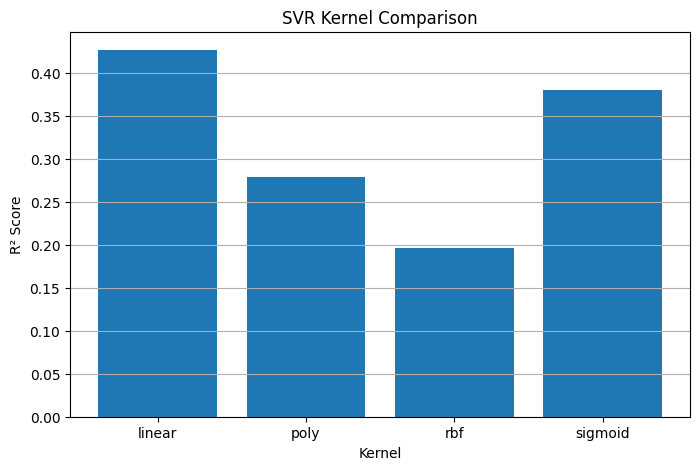

In [26]:
plt.figure(figsize=(8, 5))
plt.bar(kernel_results["Kernel"], kernel_results["R2 Score"])
plt.xlabel("Kernel")
plt.ylabel("R² Score")
plt.title("SVR Kernel Comparison")
plt.grid(axis="y")
plt.show()

In [27]:
param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.01, 0.1, 1, 5]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.01, 0.1, 1, 5],
        "gamma": ["scale", "auto", 0.01, 0.1, 1]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.1, 1],
        "gamma": ["scale", "auto"],
        "degree": [2, 3]
    },
    {
        "kernel": ["sigmoid"],
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.1, 1],
        "gamma": ["scale", "auto"]
    }
]

In [29]:
svr = SVR()
grid = GridSearchCV(
    estimator=svr,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    refit=True,
    verbose=1
)
grid.fit(X_train_scaled, y_train)
print("Model Trained!")

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Model Trained!


In [30]:
print("Best Parameters:")
print(grid.best_params_)
print("\nBest Cross-Validation R²:")
print(round(grid.best_score_, 4))

Best Parameters:
{'C': 10, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'sigmoid'}

Best Cross-Validation R²:
0.4415


In [31]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results[
    [
        "param_kernel",
        "param_C",
        "param_epsilon",
        "mean_test_score",
        "rank_test_score"
    ]
].sort_values(by="rank_test_score").head(10)

,param_kernel,param_C,param_epsilon,mean_test_score,rank_test_score
137,sigmoid,10.0,0.10,0.441548,1
7,linear,1.0,5.00,0.440497,2
5,linear,1.0,0.10,0.439601,3
139,sigmoid,10.0,1.00,0.439540,4
4,linear,1.0,0.01,0.439521,5
6,linear,1.0,1.00,0.439269,6
138,sigmoid,10.0,1.00,0.438634,7
136,sigmoid,10.0,0.10,0.438394,8
11,linear,10.0,5.00,0.425417,9
93,rbf,100.0,5.00,0.424895,10


In [32]:
best_svr = grid.best_estimator_
y_pred = best_svr.predict(X_test_scaled)
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
comparison.head(10)

,Actual,Predicted
0,219.0,139.374741
1,70.0,169.824472
2,202.0,140.740486
3,230.0,247.091247
4,111.0,125.055528
5,84.0,73.918429
6,242.0,241.008775
7,272.0,214.170341
8,94.0,110.185294
9,96.0,115.668401


In [33]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Best Kernel:", best_svr.kernel)
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

Best Kernel: sigmoid
MAE: 44.5613
MSE: 3052.0522
RMSE: 55.2454
R² Score: 0.4239


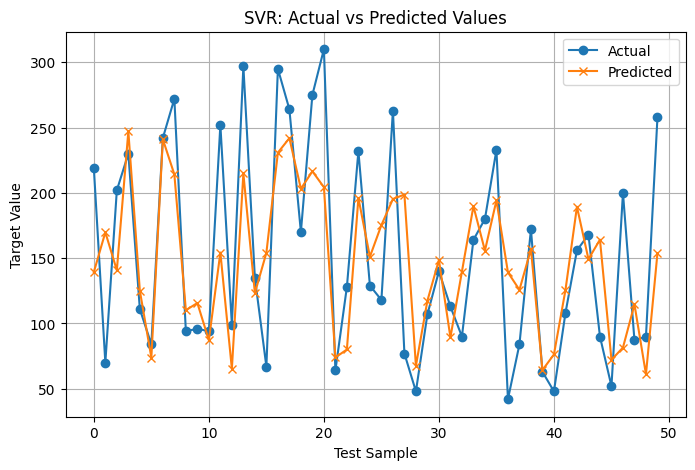

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(
    y_test.values[:50],
    label="Actual",
    marker="o"
)
plt.plot(
    y_pred[:50],
    label="Predicted",
    marker="x"
)
plt.xlabel("Test Sample")
plt.ylabel("Target Value")
plt.title("SVR: Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()